# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
# Dependencia requerida por la b?squeda p?blica; instalada de forma puntual en este entorno.
import ddgs


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import csv, hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


Keras: 3.15.1
TensorFlow: 2.20.0
GPU: []


C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 ? EN CLASE: problema y tres clases
# Problema: clasificaci?n de fotograf?as de frutas por especie.
# Las clases son visualmente distinguibles y no dependen de informaci?n escrita en la imagen.
SEARCHES = {
    "apple": [
        "whole apple fruit photograph close up",
        "red and green apple fruit isolated photograph",
    ],
    "banana": [
        "banana fruit photograph bunch close up",
        "yellow banana fruit isolated photograph",
    ],
    "orange": [
        "whole orange citrus fruit photograph close up",
        "orange fruit citrus isolated photograph",
    ],
}

SEARCHES


{'apple': ['whole apple fruit photograph close up', 'red and green apple fruit isolated photograph'], 'banana': ['banana fruit photograph bunch close up', 'yellow banana fruit isolated photograph'], 'orange': ['whole orange citrus fruit photograph close up', 'orange fruit citrus isolated photograph']}

### Antes de descargar

- **Diferencias esperadas:** forma, color y textura de la c?scara; el banano es alargado, mientras que manzanas y naranjas son redondeadas y muestran texturas distintas.
- **Im?genes incorrectas posibles:** ilustraciones, logos, frutas mezcladas, fruta cortada sin contexto, objetos de color parecido o im?genes cuyo resultado de b?squeda no corresponde al t?rmino.
- **Sesgo o fuga posible:** una clase podr?a aparecer siempre sobre el mismo fondo, en una composici?n distinta o con texto/etiquetas visibles. Im?genes duplicadas o casi id?nticas repartidas entre los conjuntos tambi?n producir?an fuga. Por eso se revisa el dataset y se separa por archivo antes de entrenar.


# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=30, min_side=120, timeout=10):
    """Descarga fotograf?as p?blicas para uso del taller y conserva procedencia en CSV.

    No elimina ni reemplaza archivos existentes. Las im?genes se guardan como copias JPEG.
    """
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0 (compatible; SI3003 course exercise)"})
    manifest = root / "image_sources.csv"
    write_header = not manifest.exists()
    seen_hashes = {
        file_sha256(path)
        for path in root.glob("*/*.jpg")
        if path.is_file()
    }

    with manifest.open("a", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=[
            "class", "filename", "query", "title", "page_url", "image_url", "search_source"
        ])
        if write_header:
            writer.writeheader()

        for class_name, queries in searches.items():
            class_dir = root / class_name
            class_dir.mkdir(parents=True, exist_ok=True)
            saved = len(list(class_dir.glob("*.jpg")))
            print(f"\n=== {class_name} ===")

            for query in queries:
                print(f"Buscando: {query!r}")
                try:
                    results = DDGS().images(
                        query=query,
                        safesearch="moderate",
                        max_results=images_per_query,
                        license_image="any",
                    )
                except Exception as e:
                    print("  Error en b?squeda:", type(e).__name__, str(e)[:240])
                    continue

                for result in results:
                    url = result.get("image")
                    if not url:
                        continue
                    try:
                        response = session.get(url, timeout=timeout)
                        response.raise_for_status()
                        data = response.content
                        digest = hashlib.sha256(data).hexdigest()
                        if digest in seen_hashes:
                            continue

                        with Image.open(io.BytesIO(data)) as img:
                            img.load()
                            img = img.convert("RGB")
                            if min(img.size) < min_side:
                                continue
                            while (class_dir / f"{saved:04d}.jpg").exists():
                                saved += 1
                            filename = class_dir / f"{saved:04d}.jpg"
                            img.save(filename, format="JPEG", quality=90)

                        seen_hashes.add(digest)
                        writer.writerow({
                            "class": class_name,
                            "filename": filename.name,
                            "query": query,
                            "title": result.get("title", ""),
                            "page_url": result.get("url", ""),
                            "image_url": url,
                            "search_source": result.get("source", ""),
                        })
                        csv_file.flush()
                        saved += 1
                    except Exception:
                        continue

                print(f"  Total guardadas hasta ahora: {saved}")
                time.sleep(1)

    print("\nDescarga terminada. Procedencia: data_raw/image_sources.csv")


## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# Evita volver a descargar im?genes al reejecutar el notebook si ya existe la colecci?n.
existing_counts = {name: len(list((RAW_DIR / name).glob("*.jpg"))) for name in SEARCHES}
if all(n >= 10 for n in existing_counts.values()):
    print("Se reutilizan las im?genes existentes:", existing_counts)
else:
    # Fuente p?blica de b?squeda autorizada por las instrucciones del notebook.
    download_image_dataset(SEARCHES, images_per_query=30)


Se reutilizan las im?genes existentes: {'apple': 60, 'banana': 60, 'orange': 60}


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'apple': 60, 'banana': 60, 'orange': 60}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    """Detecta archivos que TensorFlow no puede decodificar sin borrarlos."""
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))
            img = tf.io.decode_image(raw, channels=3, expand_animations=False)
            _ = img.numpy()
        except Exception as e:
            print("Imagen inv?lida (se conserva y se excluir? del split):", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    print(f"\nIm?genes inv?lidas detectadas: {len(bad_files)} (ninguna fue eliminada)")
    return bad_files


bad_files = remove_invalid_images(RAW_DIR)



Im?genes inv?lidas detectadas: 0 (ninguna fue eliminada)


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
# Las im?genes no decodificables se conservan en data_raw y se excluyen de la partici?n.
print(f"? Im?genes t?cnicamente inv?lidas detectadas: {len(bad_files)}")


? Im?genes t?cnicamente inv?lidas detectadas: 0


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

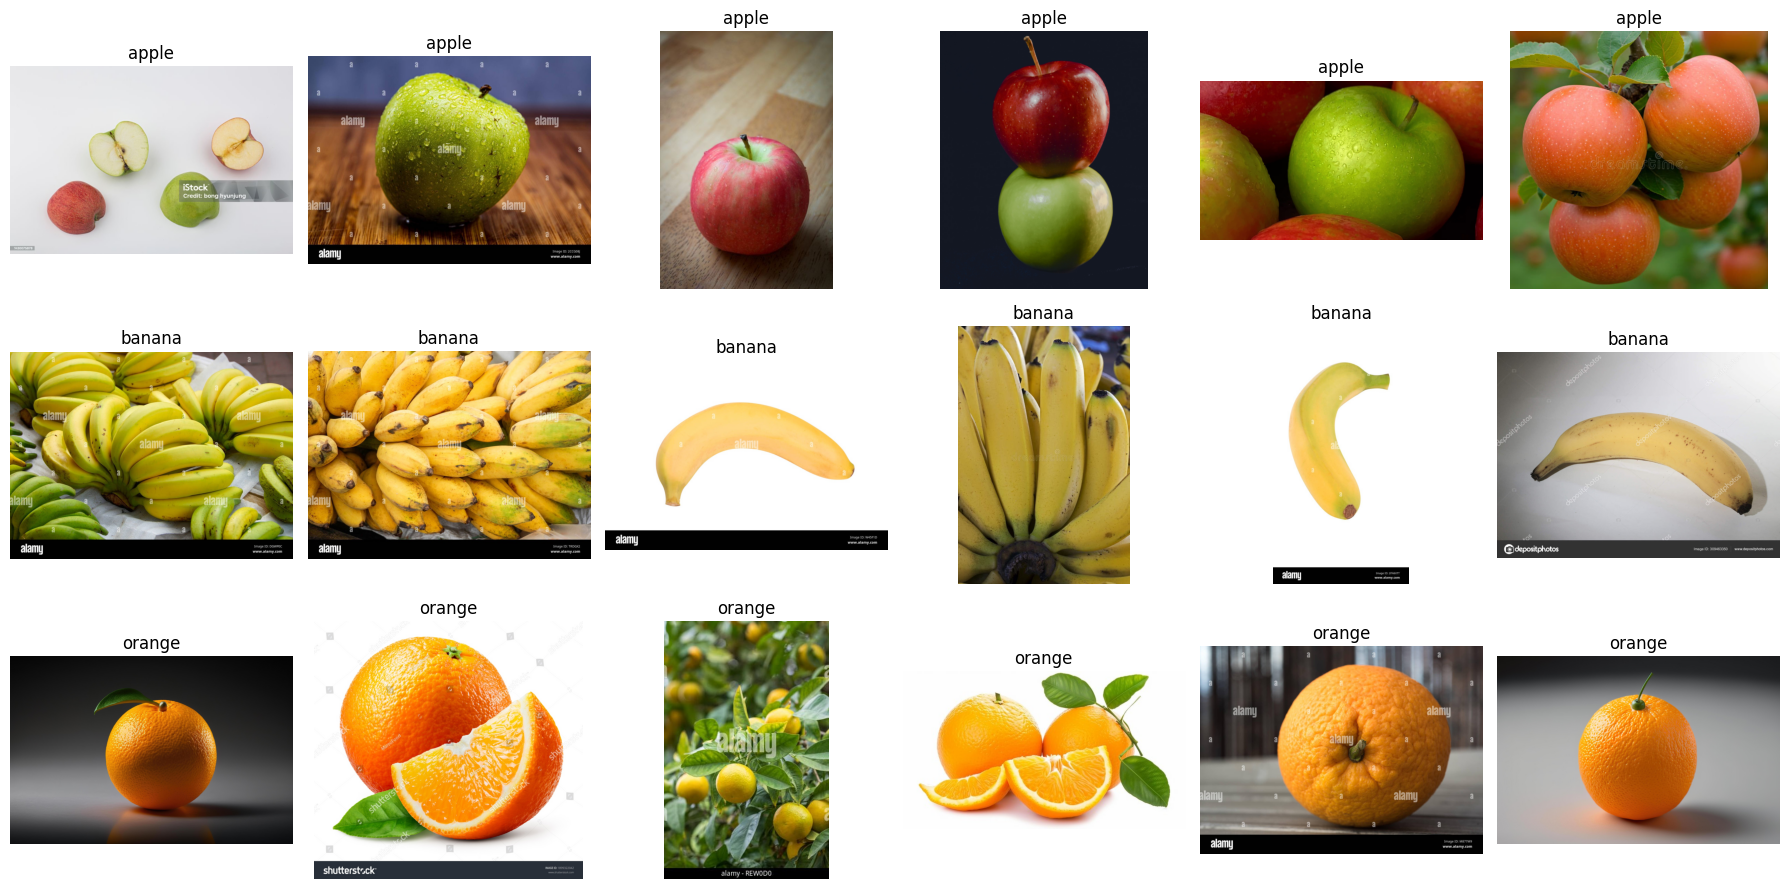

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Se descargaron 60 archivos por clase (`apple`, `banana`, `orange`). La inspecci?n aleatoria visual mostr? ejemplos que s? corresponden a la clase, aunque aparecen marcas de agua de bancos de im?genes y fondos/encuadres variados; son posibles sesgos que limitan la generalizaci?n y las im?genes no deben redistribuirse sin comprobar sus derechos. La validaci?n t?cnica detect? 0 archivos inv?lidos.

La b?squeda por hash perceptual encontr? 8 copias o casi copias dentro de la clase `orange`; la partici?n final excluye una copia de cada pareja. Los originales se conservan en `data_raw`.


# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset_clean")

def find_near_duplicates(source_root, max_distance=4):
    """Busca copias visualmente casi id?nticas con diferencia hash perceptual peque?a."""
    source_root = Path(source_root)
    records = []
    for path in sorted(source_root.glob("*/*.jpg")):
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("L").resize((9, 8)), dtype=np.int16)
        bits = (pixels[:, 1:] >= pixels[:, :-1]).flatten()
        records.append((path, bits))

    excluded = set()
    pairs = []
    for i, (path_i, hash_i) in enumerate(records):
        for path_j, hash_j in records[:i]:
            distance = int(np.count_nonzero(hash_i != hash_j))
            if distance <= max_distance:
                # Conserva la primera ruta ordenada y excluye la repetici?n posterior.
                duplicate = max(path_i, path_j)
                excluded.add(duplicate.relative_to(source_root).as_posix())
                pairs.append((path_j.relative_to(source_root).as_posix(),
                              path_i.relative_to(source_root).as_posix(), distance))

    print(f"Pares duplicados/casi duplicados detectados (dHash <= {max_distance}): {len(pairs)}")
    for first, second, distance in pairs:
        print(f"  {first} ~ {second} (distancia {distance})")
    return sorted(excluded)


def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED, excluded_files=()):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        raise FileExistsError(
            f"{destination_root} ya existe; no se sobrescribi?. Elige una ruta nueva para repetir el split."
        )
    excluded = {Path(p).resolve() for p in excluded_files}
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = [p for p in class_dir.glob("*.jpg") if p.resolve() not in excluded]
        rng.shuffle(files)
        n = len(files)
        if n < 10:
            raise ValueError(f"La clase {class_dir.name!r} solo tiene {n} im?genes v?lidas; se requieren al menos 10 para el split.")
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

# Copias/casi copias quedan fuera del split, pero sus archivos originales se preservan.
SEMANTIC_EXCLUSIONS = find_near_duplicates(RAW_DIR)
EXCLUDED_FILES = list(bad_files) + [RAW_DIR / p for p in SEMANTIC_EXCLUSIONS]
split_dataset(RAW_DIR, SPLIT_DIR, excluded_files=EXCLUDED_FILES)
print("Exclusiones del split:", SEMANTIC_EXCLUSIONS)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))


Pares duplicados/casi duplicados detectados (dHash <= 4): 8
  orange/0017.jpg ~ orange/0043.jpg (distancia 0)
  orange/0021.jpg ~ orange/0050.jpg (distancia 0)
  orange/0000.jpg ~ orange/0051.jpg (distancia 1)
  orange/0019.jpg ~ orange/0052.jpg (distancia 0)
  orange/0024.jpg ~ orange/0053.jpg (distancia 0)
  orange/0002.jpg ~ orange/0055.jpg (distancia 0)
  orange/0018.jpg ~ orange/0056.jpg (distancia 0)
  orange/0003.jpg ~ orange/0057.jpg (distancia 0)
Exclusiones del split: ['orange/0043.jpg', 'orange/0050.jpg', 'orange/0051.jpg', 'orange/0052.jpg', 'orange/0053.jpg', 'orange/0055.jpg', 'orange/0056.jpg', 'orange/0057.jpg']
train {'apple': 42, 'banana': 42, 'orange': 36}
validation {'apple': 9, 'banana': 9, 'orange': 7}
test {'apple': 9, 'banana': 9, 'orange': 9}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 120 files belonging to 3 classes.
Found 25 files belonging to 3 classes.
Found 27 files belonging to 3 classes.
['apple', 'banana', 'orange']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)      

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

In [13]:
# TODO 3 ? entrenamiento de la cabeza con la base EfficientNet congelada
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)


Epoch 1/10

1/4 ━━━━━━━━━━━━━━━━━━━━ 26s 9s/step - accuracy: 0.5000 - loss: 1.0941
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 541ms/step - accuracy: 0.4688 - loss: 1.0837
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 551ms/step - accuracy: 0.4896 - loss: 1.0654
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.4917 - loss: 1.0501
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.4917 - loss: 1.0501 - val_accuracy: 0.7600 - val_loss: 0.8391
Epoch 2/10

1/4 ━━━━━━━━━━━━━━━━━━━━ 2s 847ms/step - accuracy: 0.6562 - loss: 0.8338
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 616ms/step - accuracy: 0.6875 - loss: 0.8230
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 585ms/step - accuracy: 0.7292 - loss: 0.7969
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.7500 - loss: 0.7836
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 741ms/step - accuracy: 0.7500 - loss: 0.7836 - val_accuracy: 0.9600 - val_loss: 0.6122
Epoch 3/10

1/4 ━━━━━━━━━━━━━━━━━━━━ 2s 835ms/step - accuracy: 0.8750 - loss: 0.6550
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 529ms/step - accuracy: 0.9219 - loss: 0.6099
3/4 ━━━━

C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

notebooks\lecture8\transfer_learning\taller_transfer_learning_datos_propios_keras3.ipynb:cell30:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
notebooks\lecture8\transfer_learning\taller_transfer_learning_datos_propios_keras3.ipynb:cell30:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


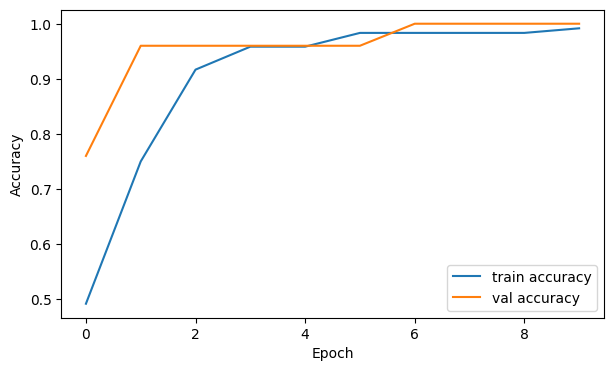

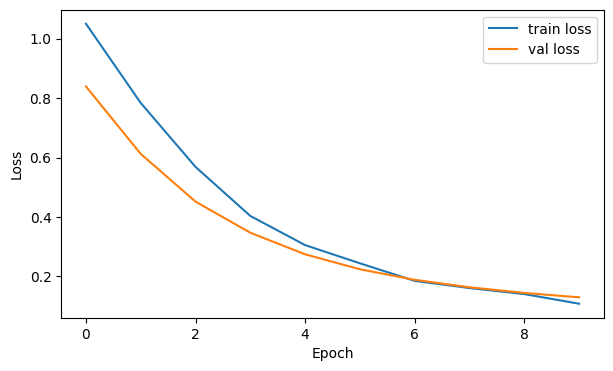

In [14]:
# Curvas de accuracy y loss en entrenamiento y validaci?n.
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


# PUNTO DE CONTROL ? FIN DEL TRABAJO EN CLASE

- [x] 3 clases definidas;
- [x] t?rminos de b?squeda documentados;
- [x] im?genes descargadas desde DDGS;
- [x] dataset inspeccionado y limpieza t?cnica/perceptual documentada;
- [x] separaci?n `train / validation / test` sin duplicados perceptuales detectados;
- [x] EfficientNetB0 con pesos de ImageNet;
- [x] backbone congelado durante el primer entrenamiento;
- [x] nueva cabeza de clasificaci?n;
- [x] entrenamiento completado;
- [x] accuracy y val_accuracy reportadas en la celda de entrenamiento.

**No uses el conjunto de test para tomar decisiones de ajuste.**

---

# PARTE B ? TRABAJO EN CASA

La evaluaci?n, matriz de confusi?n, fine-tuning, comparaci?n y an?lisis se ejecutan en las celdas siguientes.


# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9630


              precision    recall  f1-score   support

       apple      1.000     0.889     0.941         9
      banana      1.000     1.000     1.000         9
      orange      0.900     1.000     0.947         9

    accuracy                          0.963        27
   macro avg      0.967     0.963     0.963        27
weighted avg      0.967     0.963     0.963        27



notebooks\lecture8\transfer_learning\taller_transfer_learning_datos_propios_keras3.ipynb:cell34:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


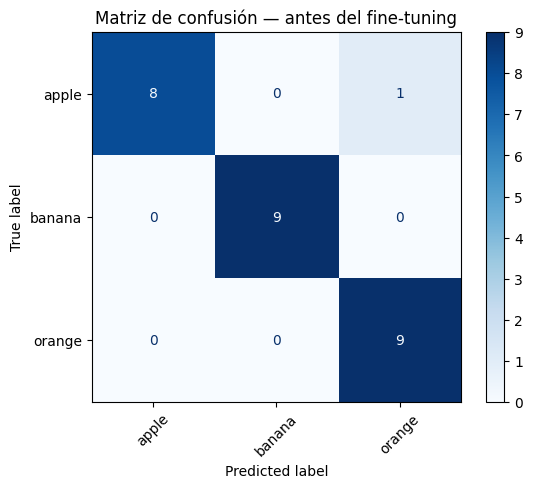

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 ? interpretaci?n de la evaluaci?n

En el test del modelo congelado se obtuvo **accuracy = 0.963 (26/27)**. La clase con mejores resultados fue `banana` (precision, recall y F1 = 1.000). La principal y ?nica confusi?n fue una imagen `apple` predicha como `orange`; por eso el recall de `apple` es 0.889 y la precision de `orange` es 0.900, aunque la accuracy global sea alta.

Antes de cambiar el modelo conviene mejorar el dataset: a?adir variedad de manzanas anaranjadas/rosadas y de naranjas en fondos parecidos, revisar las marcas de agua y conservar la diversidad de escenas. El test se us? para la evaluaci?n solicitada; la selecci?n del fine-tuning (20 capas, tasa 1e-5 y seis ?pocas con parada temprana) sigui? los par?metros del taller y se guio por validation.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# Se adaptan las ?ltimas 20 capas; se conserva congelada la normalizaci?n por lotes.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)


Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [18]:
# TODO 5 ? fine-tuning conservador; EarlyStopping utiliza solo validation.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=[early_stopping_ft],
)


Epoch 1/6

1/4 ━━━━━━━━━━━━━━━━━━━━ 29s 10s/step - accuracy: 1.0000 - loss: 0.0944
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 601ms/step - accuracy: 1.0000 - loss: 0.0974
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.9896 - loss: 0.1088
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - accuracy: 0.9917 - loss: 0.1112
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.9917 - loss: 0.1112 - val_accuracy: 1.0000 - val_loss: 0.1217
Epoch 2/6

1/4 ━━━━━━━━━━━━━━━━━━━━ 2s 895ms/step - accuracy: 1.0000 - loss: 0.0708
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 632ms/step - accuracy: 1.0000 - loss: 0.0765
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 615ms/step - accuracy: 0.9896 - loss: 0.0932
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - accuracy: 0.9917 - loss: 0.0943
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 768ms/step - accuracy: 0.9917 - loss: 0.0943 - val_accuracy: 1.0000 - val_loss: 0.1154
Epoch 3/6

1/4 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 1.0000 - loss: 0.1186
2/4 ━━━━━━━━━━━━━━━━━━━━ 1s 697ms/step - accuracy: 1.0000 - loss: 0.0971
3/4 ━━━━━━━━━

C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9630
Después del fine-tuning: 0.9630
Diferencia              : +0.0000


              precision    recall  f1-score   support

       apple      1.000     0.889     0.941         9
      banana      1.000     1.000     1.000         9
      orange      0.900     1.000     0.947         9

    accuracy                          0.963        27
   macro avg      0.967     0.963     0.963        27
weighted avg      0.967     0.963     0.963        27



notebooks\lecture8\transfer_learning\taller_transfer_learning_datos_propios_keras3.ipynb:cell42:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


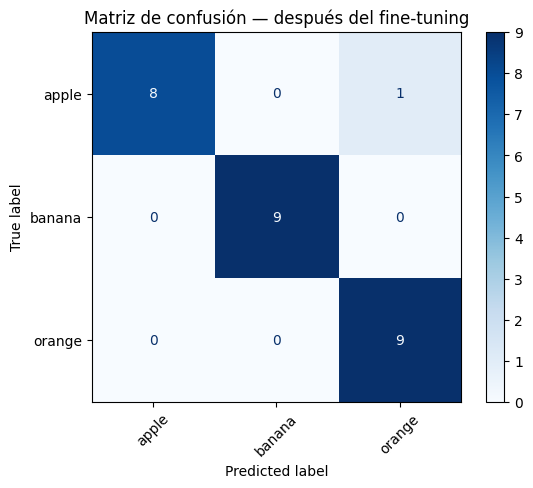

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

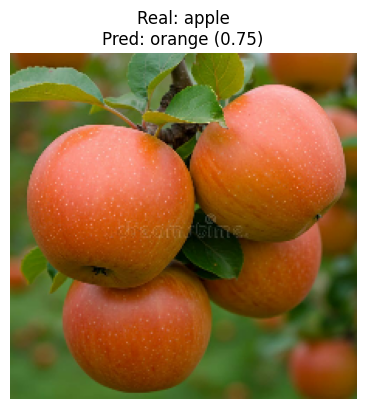

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 ? an?lisis de errores y conclusiones

En el test final hubo **un solo error** de 27 im?genes; por tanto no es posible analizar cinco errores reales sin inventarlos. Se analiza el caso disponible.

| Imagen/error | Clase real | Predicci?n | Causa probable | ?C?mo lo mejorar?as? |
|---|---|---|---|---|
| `dataset_clean/test/apple/0015.jpg` | apple | orange (confianza 0.75) | Grupo de manzanas rosadas/anaranjadas entre follaje verde: el color c?lido y la escena pueden parecerse a naranjas. | Incorporar m?s manzanas de tonos anaranjados y naranjas en escenas/fondos variados; verificar con m?s ejemplos que el modelo usa forma y textura, no solo color. |

**Conclusiones.** Construir el dataset mostr? que los resultados de b?squeda incluyen variaci?n ?til, pero tambi?n marcas de agua y copias casi id?nticas. Se detectaron ocho pares de duplicados/casi duplicados en `orange`; se excluy? una copia de cada par del split final y se conservaron los archivos originales. La inspecci?n aleatoria no mostr? etiquetas obviamente incorrectas; quedan como limitaci?n los posibles sesgos de fondo y las licencias que se deben verificar antes de redistribuir las im?genes.

La accuracy de test fue **0.963 antes y despu?s del fine-tuning** (cambio **0.000**). El ajuste no mejor? la accuracy final, aunque la accuracy de validaci?n alcanz? 1.000; con solo 27 im?genes en test, cada error cambia la m?trica en 3.7 puntos porcentuales. Primero ampliar?a y diversificar?a el dataset, luego evaluar?a con m?s datos independientes; no cambiar?a la arquitectura con esta evidencia.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# ?? Cierre conceptual ? ENTREGA

En **feature extraction** se mantiene fija la base preentrenada y se aprenden los pesos de la nueva cabeza clasificadora para las clases del dataset. La representaci?n visual inicial proviene de los pesos aprendidos previamente con ImageNet.

En **fine-tuning** se permite actualizar un grupo peque?o de capas finales de esa base, con una tasa de aprendizaje baja; as? se ajustan algunas representaciones al dominio de frutas sin borrar de golpe el conocimiento inicial.

Al entrenar una CNN **desde cero**, todos sus par?metros se inicializan sin esos pesos de ImageNet y deben aprender las caracter?sticas visuales a partir del dataset del taller. Eso suele requerir muchos m?s datos y entrenamiento.


# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ? Checklist de entrega

### Evidencia del trabajo en clase
- [x] Problema y clases definidos.
- [x] Dataset construido y revisado.
- [x] Train / validation / test creados; duplicados perceptuales excluidos de la partici?n final.
- [x] Primer modelo con backbone congelado entrenado y curvas guardadas.

### Trabajo en casa
- [x] Evaluaci?n sobre test.
- [x] Matriz de confusi?n.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparaci?n antes vs. despu?s del fine-tuning.
- [x] Error real disponible analizado; solo hubo 1 error en el test, por lo que no hab?a cinco para analizar.
- [x] Conclusi?n final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.


# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |